In [1]:
!pip install numpy pandas scikit-learn xgboost ucimlrepo matplotlib seaborn joblib ipykernel jupyter

  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached anyio-4.16.0-py3-none-any.whl.metadata (4.7 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached prometheus_client-0.26.0-py3-none-any.whl.metadata (2.1 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (2.4 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 25.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 83.3 MB/s  0:00:00m0:00:01
Using cached httpx-0.28.1-py3-none-any.whl (73 kB)
Using cached httpcore-1.0.9-py3-none-any.whl (78 kB)
Using cached anyio-4.16.0-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 76.0 MB/s  0:00:00
Using cached h11-0.16.0-py3-none-any.whl (37 kB)
Using cached idna-3.20-py3-non

In [4]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve,
    ConfusionMatrixDisplay, classification_report,
)

ROOT = Path.cwd()
if not (ROOT / 'src' / 'data.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'data.py').exists():
    raise FileNotFoundError('Run this notebook from repository root or project-notebooks/')
sys.path.insert(0, str(ROOT))

from src.data import load_dataset, split, make_preprocessor
from src.corrupt import inject_missing_mcar, inject_missing_mnar, flip_labels, perturb_features

split_seed = 42
validation_split = 0.25
experiment_seeds = [42, 43, 44]
dataset_names = ['adult', 'ai4i']
model_name = 'logistic regression'

results_dir = ROOT / 'results' / 'logistic_regression'
models_dir = ROOT / 'models' / 'logistic_regression'
results_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

In [5]:
clean_data = {}
split_sizes = []

for name in dataset_names:
    X, y = load_dataset(name)
    X_train_full, X_test, y_train_full, y_test = split(X, y, seed=split_seed)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=validation_split,
        stratify=y_train_full, random_state=split_seed
    )
    clean_data[name] = dict(X_train=X_train, X_val=X_val, X_test=X_test,
                            y_train=y_train, y_val=y_val, y_test=y_test)
    split_sizes.append(dict(dataset=name, train=len(X_train), validation=len(X_val),
                            test=len(X_test), positive_rate=float(y.mean())))

split_df = pd.DataFrame(split_sizes)
display(split_df)

,dataset,train,validation,test,positive_rate
0,adult,24863,8288,8288,0.239388
1,ai4i,6000,2000,2000,0.033900


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipelines = {}

for dataset_name in dataset_names:
    data = clean_data[dataset_name]

    pipelines[dataset_name] = Pipeline([
        ("preprocess", make_preprocessor(
            data["X_train"], mode="impute"
        )),
        ("model", LogisticRegression(
            solver="lbfgs",
            max_iter=3000,
            random_state=split_seed
        ))
    ])

    print(f"Pipeline created for {dataset_name}")

Pipeline created for adult
Pipeline created for ai4i


In [7]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=split_seed
)

best_params = {}
searches = {}
search_results = []

for dataset_name in dataset_names:

    print(f"\nTuning Logistic Regression on {dataset_name}")

    data = clean_data[dataset_name]

    search = GridSearchCV(
        estimator=pipelines[dataset_name],
        param_grid=param_grid,
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=False,
        verbose=1
    )

    # Fit GridSearchCV
    search.fit(
        data["X_train"],
        data["y_train"]
    )

    # Store search object
    searches[dataset_name] = search

    # Extract best hyperparameters
    best_params[dataset_name] = {
        key.replace("model__", ""): value
        for key, value in search.best_params_.items()
    }

    # Store results
    search_results.append({
        "dataset": dataset_name,
        "best_C": best_params[dataset_name]["C"],
        "best_class_weight": str(
            best_params[dataset_name]["class_weight"]
        ),
        "best_cv_average_precision": search.best_score_
    })

best_params_df = pd.DataFrame(search_results)

print("\nBest Hyperparameters")
print(best_params_df.round(4).to_string(index=False))


Tuning Logistic Regression on adult
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Tuning Logistic Regression on ai4i
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best Hyperparameters
dataset  best_C best_class_weight  best_cv_average_precision
  adult       1              None                     0.7698
   ai4i      10              None                     0.4722


In [8]:
def make_lr_pipeline(X_train, dataset_name, seed):
    return Pipeline([
        ("preprocess", make_preprocessor(X_train, mode="impute")),
        ("model", LogisticRegression(solver="lbfgs", max_iter=3000, random_state=seed,
                                     **best_params[dataset_name])),
    ])


def best_f1_threshold(y_true, y_score):
    # pick the threshold with the best F1 on validation instead of using 0.5
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_score)
    f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    return thresholds[np.argmax(f1s[:-1])]


def metric_row(y_true, y_score, threshold):
    y_pred = (y_score >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "average_precision": average_precision_score(y_true, y_score),
    }


normal_models, normal_thresholds, training_times = {}, {}, {}

for dataset_name in dataset_names:
    data = clean_data[dataset_name]
    for seed in experiment_seeds:
        model = make_lr_pipeline(data["X_train"], dataset_name, seed)
        start_time = time.perf_counter()
        model.fit(data["X_train"], data["y_train"])
        training_times[(dataset_name, seed)] = time.perf_counter() - start_time
        normal_models[(dataset_name, seed)] = model
        normal_thresholds[(dataset_name, seed)] = best_f1_threshold(
            data["y_val"], model.predict_proba(data["X_val"])[:, 1])
        print(f"Training time for {dataset_name} with seed {seed}: "
              f"{training_times[(dataset_name, seed)]:.2f} seconds and best threshold: "
              f"{normal_thresholds[(dataset_name, seed)]:.2f}")


Training time for adult with seed 42: 0.08 seconds and best threshold: 0.35
Training time for adult with seed 43: 0.06 seconds and best threshold: 0.35
Training time for adult with seed 44: 0.06 seconds and best threshold: 0.35
Training time for ai4i with seed 42: 0.01 seconds and best threshold: 0.24
Training time for ai4i with seed 43: 0.01 seconds and best threshold: 0.24
Training time for ai4i with seed 44: 0.01 seconds and best threshold: 0.24


Validation

In [9]:
normal_val_metrics = []

for dataset_name in dataset_names:
    data = clean_data[dataset_name]
    for seed in experiment_seeds:
        model = normal_models[(dataset_name, seed)]
        threshold = normal_thresholds[(dataset_name, seed)]
        normal_val_metrics.append({
            "dataset": dataset_name,
            "seed": seed,
            "threshold": threshold,
            **metric_row(data["y_val"], model.predict_proba(data["X_val"])[:, 1], threshold),
            # training score, to compare training vs validation for over/underfitting
            "train_average_precision": average_precision_score(
                data["y_train"], model.predict_proba(data["X_train"])[:, 1]),
            "training_seconds": training_times[(dataset_name, seed)],
        })

normal_val_df = pd.DataFrame(normal_val_metrics)
normal_val_df.round(4)

,dataset,seed,threshold,accuracy,precision,recall,f1,average_precision,train_average_precision,training_seconds
0,adult,42,0.3543,0.8512,0.6694,0.7480,0.7065,0.7815,0.773,0.0821
1,adult,43,0.3543,0.8512,0.6694,0.7480,0.7065,0.7815,0.773,0.0592
2,adult,44,0.3543,0.8512,0.6694,0.7480,0.7065,0.7815,0.773,0.0586
3,ai4i,42,0.2411,0.9615,0.4348,0.4412,0.4380,0.4045,0.477,0.0060
4,ai4i,43,0.2411,0.9615,0.4348,0.4412,0.4380,0.4045,0.477,0.0055
5,ai4i,44,0.2411,0.9615,0.4348,0.4412,0.4380,0.4045,0.477,0.0058


Test

In [10]:
normal_test_metrics = []

for dataset_name in dataset_names:
    data = clean_data[dataset_name]
    for seed in experiment_seeds:
        model = normal_models[(dataset_name, seed)]
        threshold = normal_thresholds[(dataset_name, seed)]
        normal_test_metrics.append({
            "dataset": dataset_name,
            "seed": seed,
            "threshold": threshold,
            **metric_row(data["y_test"], model.predict_proba(data["X_test"])[:, 1], threshold),
            "hyperparameters": best_params[dataset_name],
        })

    model = normal_models[(dataset_name, experiment_seeds[0])]
    joblib.dump({
        "preprocessor": model.named_steps["preprocess"],
        "model": model.named_steps["model"],
        "threshold": normal_thresholds[(dataset_name, experiment_seeds[0])],
    }, models_dir / f"{dataset_name}_clean.joblib")

normal_test_df = pd.DataFrame(normal_test_metrics)

#save results
clean_results_dir = results_dir / "clean"
clean_results_dir.mkdir(parents=True, exist_ok=True)
normal_val_df.to_csv(clean_results_dir / "validation.csv", index=False)
normal_test_df.to_csv(clean_results_dir / "test.csv", index=False)
normal_test_df.round(4)

,dataset,seed,threshold,accuracy,precision,recall,f1,average_precision,hyperparameters
0,adult,42,0.3543,0.8441,0.6510,0.7520,0.6978,0.7819,"{'C': 1, 'class_weight': None}"
1,adult,43,0.3543,0.8441,0.6510,0.7520,0.6978,0.7819,"{'C': 1, 'class_weight': None}"
2,adult,44,0.3543,0.8441,0.6510,0.7520,0.6978,0.7819,"{'C': 1, 'class_weight': None}"
3,ai4i,42,0.2411,0.9650,0.4839,0.4412,0.4615,0.4171,"{'C': 10, 'class_weight': None}"
4,ai4i,43,0.2411,0.9650,0.4839,0.4412,0.4615,0.4171,"{'C': 10, 'class_weight': None}"
5,ai4i,44,0.2411,0.9650,0.4839,0.4412,0.4615,0.4171,"{'C': 10, 'class_weight': None}"


Corrupted Data

In [11]:
corruption_rates = [0.1, 0.2, 0.3, 0.4]
corruption_seed = 42
noise_scale = 1.0

corruption_types = ["mcar", "mcar_test", "mnar", "noise", "label_flip"]
MNAR_COLUMNS = {"adult": ["education_num"], "ai4i": ["Tool_wear", "Torque"]}

corrupted_val_metrics, corrupted_test_metrics, missingness = [], [], []

for corruption_type in corruption_types:
    corrupted_results_dir = results_dir / corruption_type
    corrupted_results_dir.mkdir(parents=True, exist_ok=True)

    for dataset_name in dataset_names:
        for missing_rate in corruption_rates:
            print(f"Training {model_name} on {dataset_name} with {missing_rate:.0%} {corruption_type}")

            # use the same splits as the normal models
            data = clean_data[dataset_name].copy()
            train_rng = np.random.default_rng(corruption_seed)
            val_rng = np.random.default_rng(corruption_seed + 1)
            test_rng = np.random.default_rng(corruption_seed + 2)

            # corrupt the training and validation sets, the test set stays clean (except for mcar_test)
            if corruption_type in ["mcar", "mcar_test"]:
                data["X_train"] = inject_missing_mcar(data["X_train"], missing_rate, rng=train_rng)
                data["X_val"] = inject_missing_mcar(data["X_val"], missing_rate, rng=val_rng)
                if corruption_type == "mcar_test":
                    data["X_test"] = inject_missing_mcar(data["X_test"], missing_rate, rng=test_rng)
            elif corruption_type == "mnar":
                # value-dependent missingness on the most informative features (EDA): larger values go missing more often
                for column in MNAR_COLUMNS[dataset_name]:
                    data["X_train"] = inject_missing_mnar(data["X_train"], missing_rate, rng=train_rng, column=column)
                    data["X_val"] = inject_missing_mnar(data["X_val"], missing_rate, rng=val_rng, column=column)
            elif corruption_type == "noise":
                data["X_train"] = perturb_features(data["X_train"], missing_rate, rng=train_rng, noise_scale=noise_scale)
                data["X_val"] = perturb_features(data["X_val"], missing_rate, rng=val_rng, noise_scale=noise_scale)
            elif corruption_type == "label_flip":
                data["y_train"] = flip_labels(data["y_train"], missing_rate, rng=train_rng)
                data["y_val"] = flip_labels(data["y_val"], missing_rate, rng=val_rng)

            #check missingness
            missingness.append({
                "corruption_type": corruption_type,
                "dataset": dataset_name,
                "missing_rate": missing_rate,
                "corruption_seed": corruption_seed,
                "training_missing_pct": 100 * data["X_train"].isna().to_numpy().mean(),
                "validation_missing_pct": 100 * data["X_val"].isna().to_numpy().mean(),
                "test_missing_pct": 100 * data["X_test"].isna().to_numpy().mean(),
            })

            for seed in experiment_seeds:
                # same hyperparameters as the normal models; the pipeline refits
                # its preprocessing (imputation, encoding) on the corrupted training set
                model = make_lr_pipeline(data["X_train"], dataset_name, seed)
                start_time = time.perf_counter()
                model.fit(data["X_train"], data["y_train"])
                training_seconds = time.perf_counter() - start_time

                # pick the threshold with the best F1 on validation, using the clean validation labels
                # (with flipped labels, the best-F1 threshold is "predict everything positive")
                threshold = best_f1_threshold(clean_data[dataset_name]["y_val"],
                                              model.predict_proba(data["X_val"])[:, 1])

                for X_eval, y_eval, metrics_list in [(data["X_val"], data["y_val"], corrupted_val_metrics),
                                                     (data["X_test"], data["y_test"], corrupted_test_metrics)]:
                    prob = model.predict_proba(X_eval)[:, 1]
                    metrics_list.append({
                        "corruption_type": corruption_type,
                        "dataset": dataset_name,
                        "missing_rate": missing_rate,
                        "corruption_seed": corruption_seed,
                        "seed": seed,
                        "threshold": threshold,
                        **metric_row(y_eval, prob, threshold),
                        "training_seconds": training_seconds,
                        "hyperparameters": best_params[dataset_name],
                    })

        #save results after each corruption type and dataset
        corrupted_val_df = pd.DataFrame(corrupted_val_metrics)
        corrupted_test_df = pd.DataFrame(corrupted_test_metrics)
        corrupted_val_df[corrupted_val_df.corruption_type == corruption_type].to_csv(corrupted_results_dir / "validation.csv", index=False)
        corrupted_test_df[corrupted_test_df.corruption_type == corruption_type].to_csv(corrupted_results_dir / "test.csv", index=False)
        pd.DataFrame(missingness).to_csv(results_dir / "missingness.csv", index=False)

#average test performance across the three seeds
test_summary = corrupted_test_df.groupby(["corruption_type", "dataset", "missing_rate"])[
    ["accuracy", "precision", "recall", "f1", "average_precision"]
].agg(["mean", "std"])

test_summary.to_csv(results_dir / "test_summary.csv")
display(test_summary.round(4))

Training logistic regression on adult with 10% mcar
Training logistic regression on adult with 20% mcar
Training logistic regression on adult with 30% mcar
Training logistic regression on adult with 40% mcar
Training logistic regression on ai4i with 10% mcar
Training logistic regression on ai4i with 20% mcar
Training logistic regression on ai4i with 30% mcar
Training logistic regression on ai4i with 40% mcar
Training logistic regression on adult with 10% mcar_test
Training logistic regression on adult with 20% mcar_test
Training logistic regression on adult with 30% mcar_test
Training logistic regression on adult with 40% mcar_test
Training logistic regression on ai4i with 10% mcar_test
Training logistic regression on ai4i with 20% mcar_test
Training logistic regression on ai4i with 30% mcar_test
Training logistic regression on ai4i with 40% mcar_test
Training logistic regression on adult with 10% mnar
Training logistic regression on adult with 20% mnar
Training logistic regression on 

accuracy      precision       recall  \
                                         mean  std      mean  std    mean   
corruption_type dataset missing_rate                                        
label_flip      adult   0.1            0.8380  0.0    0.6342  0.0  0.7636   
                        0.2            0.8258  0.0    0.6079  0.0  0.7666   
                        0.3            0.8129  0.0    0.5809  0.0  0.7833   
                        0.4            0.8045  0.0    0.5717  0.0  0.7314   
                ai4i    0.1            0.9705  0.0    0.7647  0.0  0.1912   
                        0.2            0.9660  0.0    0.5000  0.0  0.2794   
                        0.3            0.9645  0.0    0.4615  0.0  0.2647   
                        0.4            0.9615  0.0    0.3784  0.0  0.2059   
mcar            adult   0.1            0.8366  0.0    0.6287  0.0  0.7757   
                        0.2            0.8363  0.0    0.6276  0.0  0.7772   
                        0.3            0.8283  0.0    0.6073  0.0  0.8004   
                        0.4            0.8348  0.0    0.6238  0.0  0.7807   
                ai4i    0.1            0.9635  0.0    0.4468  0.0  0.3088   
                        0.2            0.9620  0.0    0.3571  0.0  0.1471   
                        0.3            0.9565  0.0    0.3492  0.0  0.3235   
                        0.4            0.9605  0.0    0.3830  0.0  0.2647   
mcar_test       adult   0.1            0.8302  0.0    0.6163  0.0  0.7707   
                        0.2            0.8196  0.0    0.5982  0.0  0.7505   
                        0.3            0.7968  0.0    0.5530  0.0  0.7883   
                        0.4            0.7820  0.0    0.5315  0.0  0.7530   
                ai4i    0.1            0.9580  0.0    0.3571  0.0  0.2941   
                        0.2            0.9670  0.0    0.5385  0.0  0.2059   
                        0.3            0.9565  0.0    0.3443  0.0  0.3088   
                        0.4            0.9645  0.0    0.4545  0.0  0.2206   
mnar            adult   0.1            0.8431  0.0    0.6472  0.0  0.7581   
                        0.2            0.8493  0.0    0.6694  0.0  0.7319   
                        0.3            0.8348  0.0    0.6256  0.0  0.7722   
                        0.4            0.8339  0.0    0.6226  0.0  0.7767   
                ai4i    0.1            0.9340  0.0    0.2838  0.0  0.6176   
                        0.2            0.9205  0.0    0.2370  0.0  0.6029   
                        0.3            0.9275  0.0    0.2450  0.0  0.5441   
                        0.4            0.9025  0.0    0.1962  0.0  0.6029   
noise           adult   0.1            0.8463  0.0    0.6612  0.0  0.7339   
                        0.2            0.8351  0.0    0.6314  0.0  0.7470   
                        0.3            0.8329  0.0    0.6280  0.0  0.7404   
                        0.4            0.8283  0.0    0.6161  0.0  0.7500   
                ai4i    0.1            0.9660  0.0    0.5000  0.0  0.1618   
                        0.2            0.9620  0.0    0.3947  0.0  0.2206   
                        0.3            0.9635  0.0    0.4194  0.0  0.1912   
                        0.4            0.9655  0.0    0.4545  0.0  0.0735   

                                               f1      average_precision       
                                      std    mean  std              mean  std  
corruption_type dataset missing_rate                                           
label_flip      adult   0.1           0.0  0.6929  0.0            0.7674  0.0  
                        0.2           0.0  0.6781  0.0            0.7424  0.0  
                        0.3           0.0  0.6671  0.0            0.7256  0.0  
                        0.4           0.0  0.6418  0.0            0.6873  0.0  
                ai4i    0.1           0.0  0.3059  0.0            0.4060  0.0  
                        0.2           0.0  0.3585  0.0            0.4037  0.0  
     

Test performance as the training data gets worse

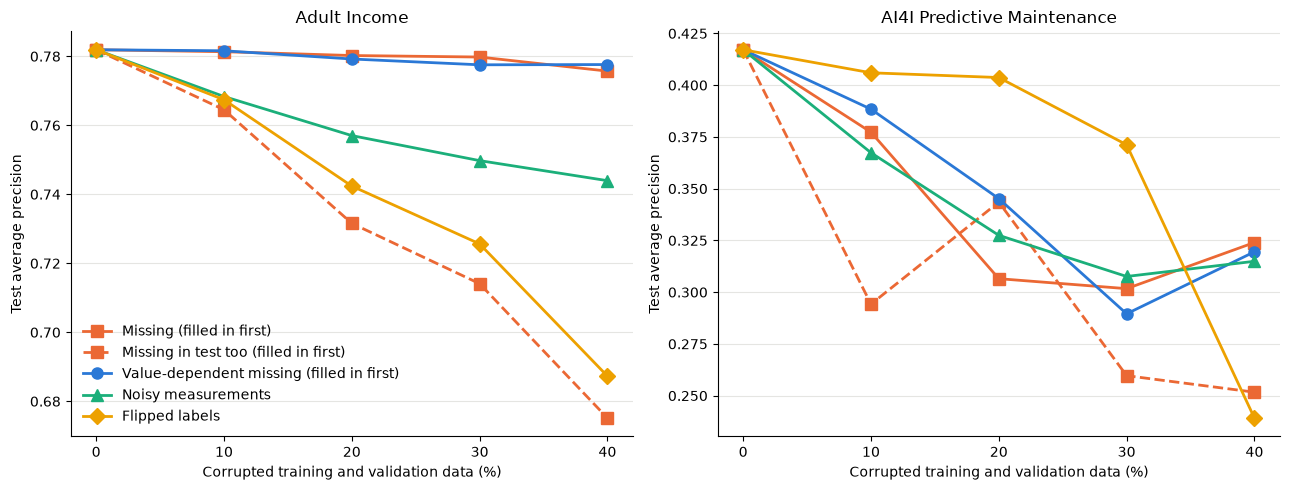

In [13]:
baseline_ap = normal_test_df.groupby("dataset")["average_precision"].mean()
plot_df = corrupted_test_df.groupby(["corruption_type", "dataset", "missing_rate"])["average_precision"].mean().reset_index()

labels = {"mcar": "Missing (filled in first)", "mcar_test": "Missing in test too (filled in first)",
          "mnar": "Value-dependent missing (filled in first)",
          "noise": "Noisy measurements", "label_flip": "Flipped labels"}
colors = {"mcar": "#eb6834", "mnar": "#2a78d6", "mcar_test": "#eb6834", "noise": "#1baf7a", "label_flip": "#eda100"}
markers = {"mcar": "s", "mnar": "o", "mcar_test": "s", "noise": "^", "label_flip": "D"}
titles = {"adult": "Adult Income", "ai4i": "AI4I Predictive Maintenance"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, dataset_name in zip(axes, dataset_names):
    for corruption_type in corruption_types:
        rows = plot_df[(plot_df.corruption_type == corruption_type) & (plot_df.dataset == dataset_name)]
        # every line starts at the clean baseline (0% corrupted)
        x = [0] + list(100 * rows.missing_rate)
        y = [baseline_ap[dataset_name]] + list(rows.average_precision)
        ax.plot(x, y, color=colors[corruption_type], marker=markers[corruption_type],
                markersize=8, linewidth=2, label=labels[corruption_type],
                linestyle="--" if corruption_type.endswith("_test") else "-")
    ax.set_title(titles[dataset_name])
    ax.set_xlabel("Corrupted training and validation data (%)")
    ax.set_ylabel("Test average precision")
    ax.set_xticks([0, 10, 20, 30, 40])
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(results_dir / "test_ap_vs_corruption.png", dpi=150)
plt.show()